In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mrsimple07/diabetes-prediction")

print("Path to dataset files:", path)

100%|██████████| 64.2k/64.2k [00:00<00:00, 36.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mrsimple07/diabetes-prediction/versions/1


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/Diabetes_prediction.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (1000, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [3]:

df.info()

print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Diagnosis distribution:")
display(df["Diagnosis"].value_counts())

print("Summary statistics:")
display(df.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               1000 non-null   int64  
 1   Glucose                   1000 non-null   float64
 2   BloodPressure             1000 non-null   float64
 3   SkinThickness             1000 non-null   float64
 4   Insulin                   1000 non-null   float64
 5   BMI                       1000 non-null   float64
 6   DiabetesPedigreeFunction  1000 non-null   float64
 7   Age                       1000 non-null   float64
 8   Diagnosis                 1000 non-null   int64  
dtypes: float64(7), int64(2)
memory usage: 70.4 KB
Missing values:


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Diagnosis,0


Duplicate rows: 0
Diagnosis distribution:


,count
Diagnosis,
0,694
1,306


Summary statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,1.77,99.44,72.18,23.28,84.58,25.43,0.45,43.28,0.31
std,1.35,19.47,13.88,1.17,74.87,3.69,0.20,14.47,0.46
min,0.00,30.57,31.40,19.37,-165.31,13.55,0.10,-0.98,0.00
25%,1.00,86.15,62.80,22.50,35.08,23.02,0.28,33.52,0.00
50%,2.00,99.46,71.91,23.28,84.44,25.46,0.45,43.63,0.00
75%,3.00,113.26,82.08,24.05,134.27,27.97,0.62,53.10,1.00
max,8.00,161.24,110.72,26.92,317.70,36.32,0.80,90.57,1.00


In [4]:

print("Diagnosis values:", sorted(df["Diagnosis"].unique()))


checks = {
    "Negative age": df["Age"] < 0,
    "Negative insulin": df["Insulin"] < 0,
    "Non-positive glucose": df["Glucose"] <= 0,
    "Non-positive BMI": df["BMI"] <= 0,
    "Negative blood pressure": df["BloodPressure"] < 0
}

for name, mask in checks.items():
    print(f"{name}: {mask.sum()} rows")

Diagnosis values: [np.int64(0), np.int64(1)]
Negative age: 2 rows
Negative insulin: 127 rows
Non-positive glucose: 0 rows
Non-positive BMI: 0 rows
Negative blood pressure: 0 rows


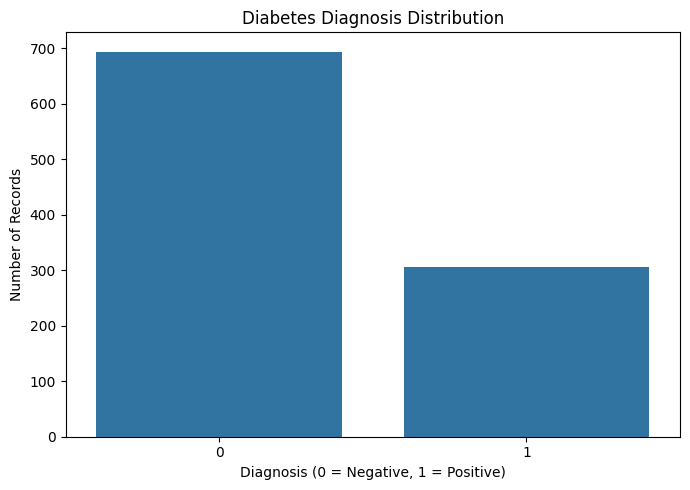

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Diagnosis")

plt.title("Diabetes Diagnosis Distribution")
plt.xlabel("Diagnosis (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

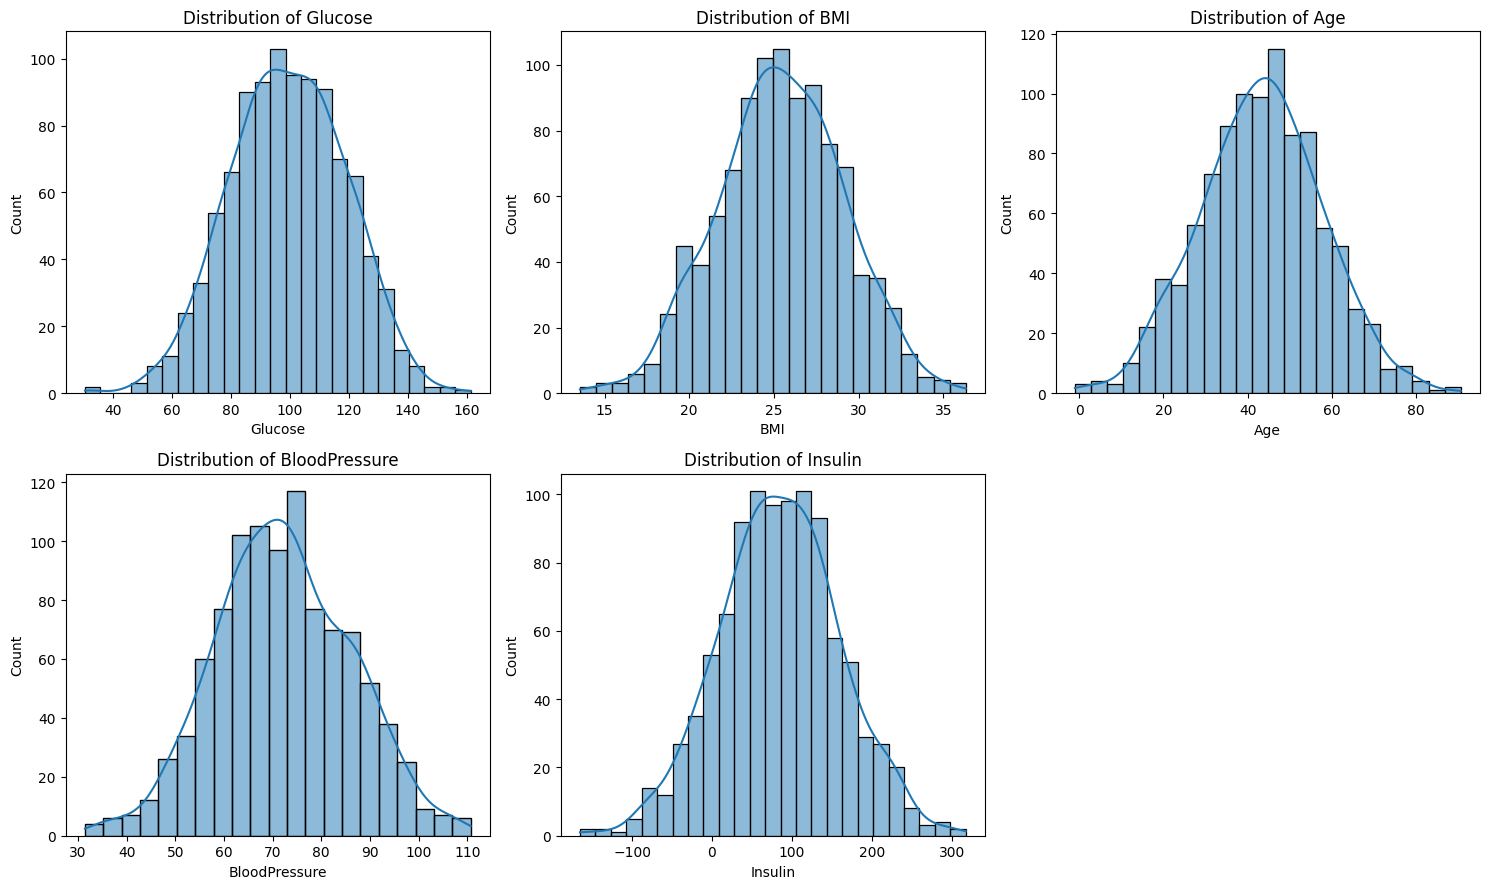

In [6]:
features = [
    "Glucose",
    "BMI",
    "Age",
    "BloodPressure",
    "Insulin"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

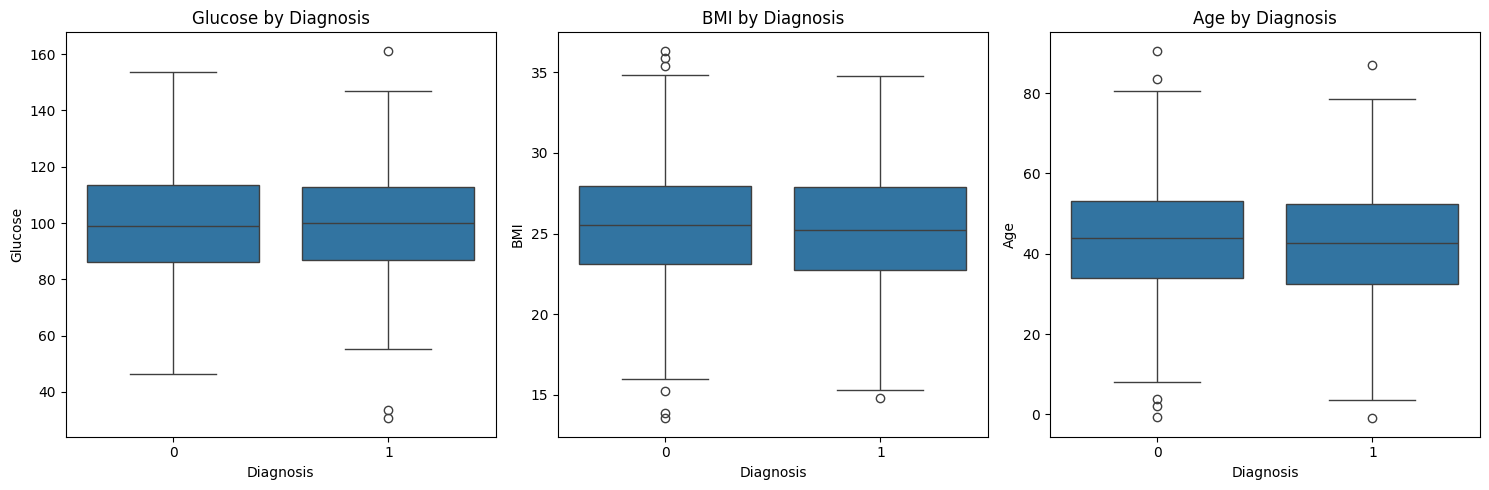

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ["Glucose", "BMI", "Age"]):
    sns.boxplot(data=df, x="Diagnosis", y=col, ax=ax)
    ax.set_title(f"{col} by Diagnosis")

plt.tight_layout()
plt.show()

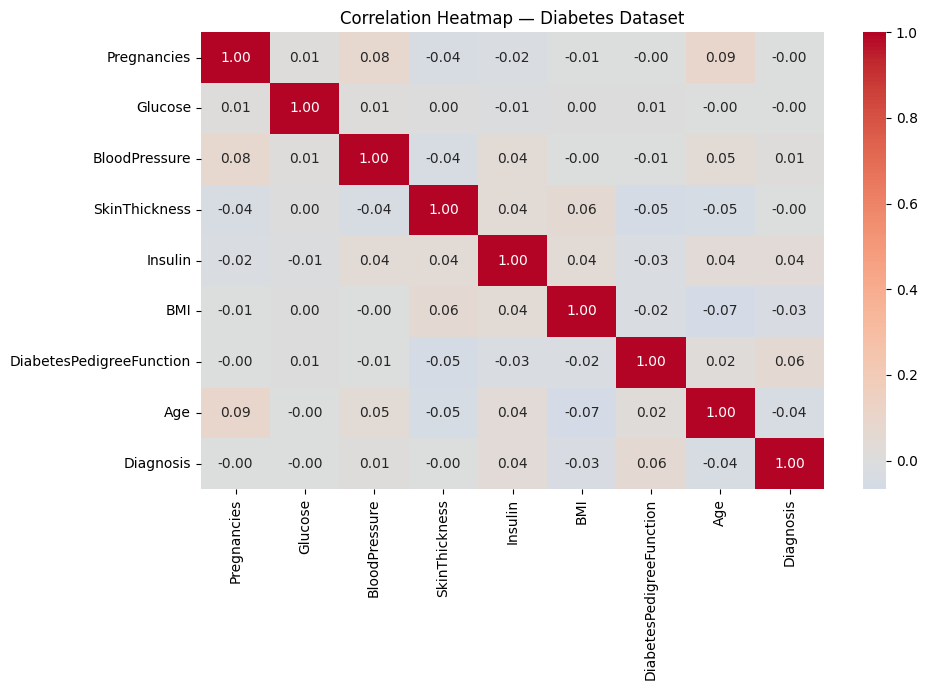

In [8]:
plt.figure(figsize=(10, 7))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap — Diabetes Dataset")
plt.tight_layout()
plt.show()

In [9]:
summary = df.groupby("Diagnosis")[features].agg(
    ["mean", "median", "std"]
).round(2)

display(summary)

Glucose                   BMI                 Age                \
             mean  median    std   mean median   std   mean median    std   
Diagnosis                                                                   
0           99.50   98.92  19.36  25.52  25.56  3.63  43.71  43.86  14.29   
1           99.29  100.16  19.74  25.25  25.25  3.83  42.31  42.58  14.84   

          BloodPressure               Insulin                
                   mean median    std    mean median    std  
Diagnosis                                                    
0                 72.08  71.82  13.78   82.82  83.11  73.86  
1                 72.40  71.97  14.13   88.57  88.25  77.09

In [10]:
import os

os.makedirs("diabetes_project/outputs", exist_ok=True)

df.describe().to_csv(
    "diabetes_project/outputs/summary_statistics.csv"
)

correlation.to_csv(
    "diabetes_project/outputs/correlation_matrix.csv"
)

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(
    "diabetes_project/outputs/correlation_heatmap.png",
    dpi=300
)
plt.close()

print("Analysis outputs saved successfully!")

Analysis outputs saved successfully!


In [11]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDiagnosis distribution:")
print(df["Diagnosis"].value_counts(dropna=False))

print("\nDiagnosis data type:")
print(df["Diagnosis"].dtype)

print("\nSummary statistics:")
display(df.describe().T)

print("\nCorrelation with Diagnosis:")
display(
    df.corr(numeric_only=True)["Diagnosis"]
    .sort_values(ascending=False)
)

print("\nFirst 10 rows:")
display(df.head(10))

Dataset shape: (1000, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Diagnosis']

Diagnosis distribution:
Diagnosis
0    694
1    306
Name: count, dtype: int64

Diagnosis data type:
int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,1000.0,1.771000,1.354398,0.000000,1.000000,2.000000,3.000000,8.000000
Glucose,1000.0,99.440607,19.470730,30.571402,86.145927,99.458362,113.264556,161.238939
BloodPressure,1000.0,72.179837,13.882017,31.401487,62.795447,71.909588,82.082660,110.723715
SkinThickness,1000.0,23.278316,1.173807,19.369987,22.501591,23.275225,24.052022,26.917654
Insulin,1000.0,84.582679,74.872733,-165.310033,35.076535,84.442232,134.267842,317.701852
BMI,1000.0,25.433600,3.690223,13.548818,23.022715,25.455649,27.972184,36.324598
DiabetesPedigreeFunction,1000.0,0.449383,0.199334,0.100037,0.283376,0.448219,0.619158,0.799654
Age,1000.0,43.281798,14.465398,-0.979804,33.518451,43.634273,53.098446,90.573782
Diagnosis,1000.0,0.306000,0.461060,0.000000,0.000000,0.000000,1.000000,1.000000



Correlation with Diagnosis:


,Diagnosis
Diagnosis,1.000000
DiabetesPedigreeFunction,0.060549
Insulin,0.035411
BloodPressure,0.010349
SkinThickness,-0.000014
Pregnancies,-0.001484
Glucose,-0.004971
BMI,-0.033336
Age,-0.044726



First 10 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0
5,2,108.870034,74.338518,25.390851,78.704740,20.008180,0.673117,24.893761,0
6,3,95.665270,54.157100,23.927648,130.989859,29.235840,0.461786,18.669086,1
7,0,108.353474,68.497370,22.611992,109.225691,27.724017,0.474361,44.517575,0
8,2,120.979399,50.617860,23.677139,-11.616854,21.032709,0.105676,42.743013,1
9,2,123.839177,75.067548,23.198216,181.809109,29.271195,0.622292,66.017355,0


,count,mean,median,std,min,max
Diagnosis,,,,,,
0,694,99.50,98.92,19.36,46.30,153.69
1,306,99.29,100.16,19.74,30.57,161.24


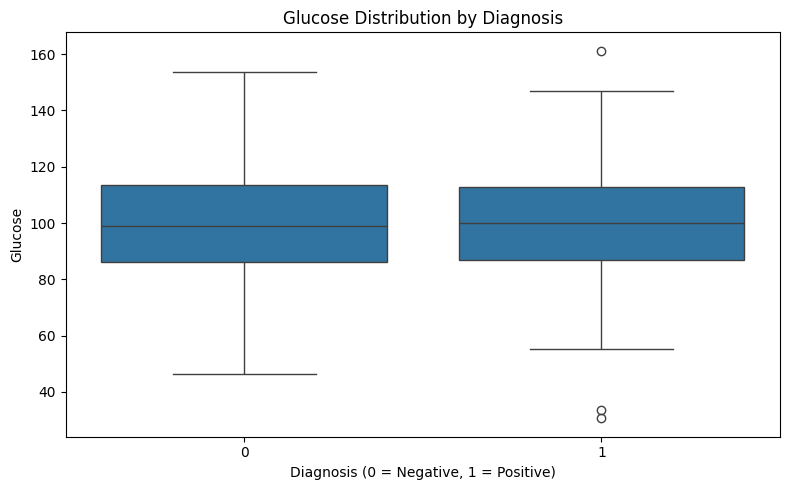

In [12]:
display(
    df.groupby("Diagnosis")["Glucose"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Diagnosis",
    y="Glucose"
)

plt.title("Glucose Distribution by Diagnosis")
plt.xlabel("Diagnosis (0 = Negative, 1 = Positive)")
plt.ylabel("Glucose")

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

TARGET = "Diagnosis"

# Use the original dataset loaded earlier
X = df[FEATURES].copy()
y = df[TARGET].copy()

# Reject invalid target labels
if y.isna().any() or not set(y.unique()).issubset({0, 1}):
    raise ValueError("Diagnosis must contain only 0 and 1.")

# Ensure all input features are numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Remove rows with impossible measurements from training
valid = (
    X.notna().all(axis=1)
    & (X["Age"] >= 0)
    & (X["Glucose"] > 0)
    & (X["BloodPressure"] > 0)
    & (X["Insulin"] >= 0)
    & (X["BMI"] > 0)
)

X = X.loc[valid]
y = y.loc[valid]

if len(X) < 20 or y.nunique() != 2:
    raise ValueError("Insufficient valid records to train the model.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model training completed.")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Test accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, predictions))

Model training completed.
Training records: 696
Testing records: 175
Test accuracy: 0.691

Classification report:
              precision    recall  f1-score   support

           0       0.69      1.00      0.82       121
           1       0.00      0.00      0.00        54

    accuracy                           0.69       175
   macro avg       0.35      0.50      0.41       175
weighted avg       0.48      0.69      0.57       175

Confusion matrix:
[[121   0]
 [ 54   0]]


In [14]:
from google.colab import files
from IPython.display import display
from io import BytesIO

print("Upload a patient CSV file.")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded.")

filename = next(iter(uploaded))

if not filename.lower().endswith(".csv"):
    raise ValueError("Please upload a CSV file.")

patient_df = pd.read_csv(BytesIO(uploaded[filename]))

missing = [col for col in FEATURES if col not in patient_df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

if patient_df.empty:
    raise ValueError("The uploaded file contains no patient records.")

patient_X = patient_df[FEATURES].apply(
    pd.to_numeric, errors="coerce"
)

if patient_X.isna().any().any():
    raise ValueError(
        "Patient file contains missing or non-numeric measurements. "
        "Please correct the file before prediction."
    )

print("Patient file loaded successfully.")
display(patient_X.head())

Upload a patient CSV file.


Saving sample_patient_diabetes_input.csv to sample_patient_diabetes_input.csv
Patient file loaded successfully.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,115,70,25,90,26.5,0.27,35


In [15]:
# Basic input validation
rules = {
    "Pregnancies": patient_X["Pregnancies"] >= 0,
    "Glucose": patient_X["Glucose"] > 0,
    "BloodPressure": patient_X["BloodPressure"] > 0,
    "SkinThickness": patient_X["SkinThickness"] >= 0,
    "Insulin": patient_X["Insulin"] >= 0,
    "BMI": patient_X["BMI"] > 0,
    "DiabetesPedigreeFunction":
        patient_X["DiabetesPedigreeFunction"] >= 0,
    "Age": patient_X["Age"] > 0
}

for feature, valid_rows in rules.items():
    if not valid_rows.all():
        raise ValueError(
            f"Invalid measurement detected in {feature}. "
            "Check the values and units."
        )

# Experimental model outputs
predicted_class = model.predict(patient_X)
probabilities = model.predict_proba(patient_X)

results = patient_df.copy()

results["Model_Class_Estimate"] = predicted_class
results["Estimated_Class_0_Probability_Percent"] = (
    probabilities[:, 0] * 100
).round(2)
results["Estimated_Class_1_Probability_Percent"] = (
    probabilities[:, 1] * 100
).round(2)

results["Interpretation"] = np.where(
    predicted_class == 1,
    "Model estimates class 1",
    "Model estimates class 0"
)

results["Status"] = "Experimental result - clinician review required"

display(results)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Model_Class_Estimate,Estimated_Class_0_Probability_Percent,Estimated_Class_1_Probability_Percent,Interpretation,Status
0,2,115,70,25,90,26.5,0.27,35,0,70.76,29.24,Model estimates class 0,Experimental result - clinician review required


In [16]:
output_file = "patient_prediction_report.csv"

results.to_csv(output_file, index=False)

print("Experimental prediction report generated.")
files.download(output_file)

Experimental prediction report generated.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>